In [1]:
import eu9_osm
import geopandas as gpd
import matplotlib.pyplot as plt

In [2]:
bbox = (-9.256325, 38.616066, -8.947334, 38.753012)
crs = "EPSG:3763"

In [3]:
# Data
routes = eu9_osm.features_from_bbox(bbox=bbox, tags={"route": "ferry"}, clip=True).to_crs(crs)
terminals = eu9_osm.features_from_bbox(bbox=bbox, tags={"amenity": "ferry_terminal"}).to_crs(crs)
water = eu9_osm.features_from_bbox(bbox=bbox, tags={"natural": ["coastline", "bay", "strait", "wetland"]}, clip=True).to_crs(crs)

tags = {"highway": ["motorway", "trunk", "primary", "secondary", "tertiary", "primary_link", "tertiary_link"]}
roads = eu9_osm.features_from_bbox(bbox=bbox, tags=tags, clip=True).to_crs(crs)

In [4]:
# Clean terminals
terminals = terminals[terminals.geometry.geom_type == "Point"]
terminals = terminals.drop_duplicates(subset="name")
# Clean roads
roads = roads[roads["geometry"].geom_type != "Point"]
# Clean water
water = water[water["geometry"].geom_type != "Point"]

In [5]:
linewidths = {
    "motorway": 0.65,
    "trunk": 0.55,
    "primary": 0.45,
    "secondary": 0.35,
    "tertiary": 0.25,
    "primary_link": 0.20,
    "tertiary_link": 0.15,
}

roads["linewidth"] = roads["highway"].map(linewidths).fillna(0.15)

In [6]:
colors = [
    "#FF4365",
    "#FF7B38",
    "#FFBC42",
    "#F9F871",
    "#A8F05C",
    "#39E6A2",
    "#20E3D0",
    "#23CBFF",
    "#538CFF",
    "#9A78FF",
    "#ED66F5",
    "#FF69A8",
]

# Roure colors
routes["color"] = [colors[i % len(colors)] for i in range(len(routes))]

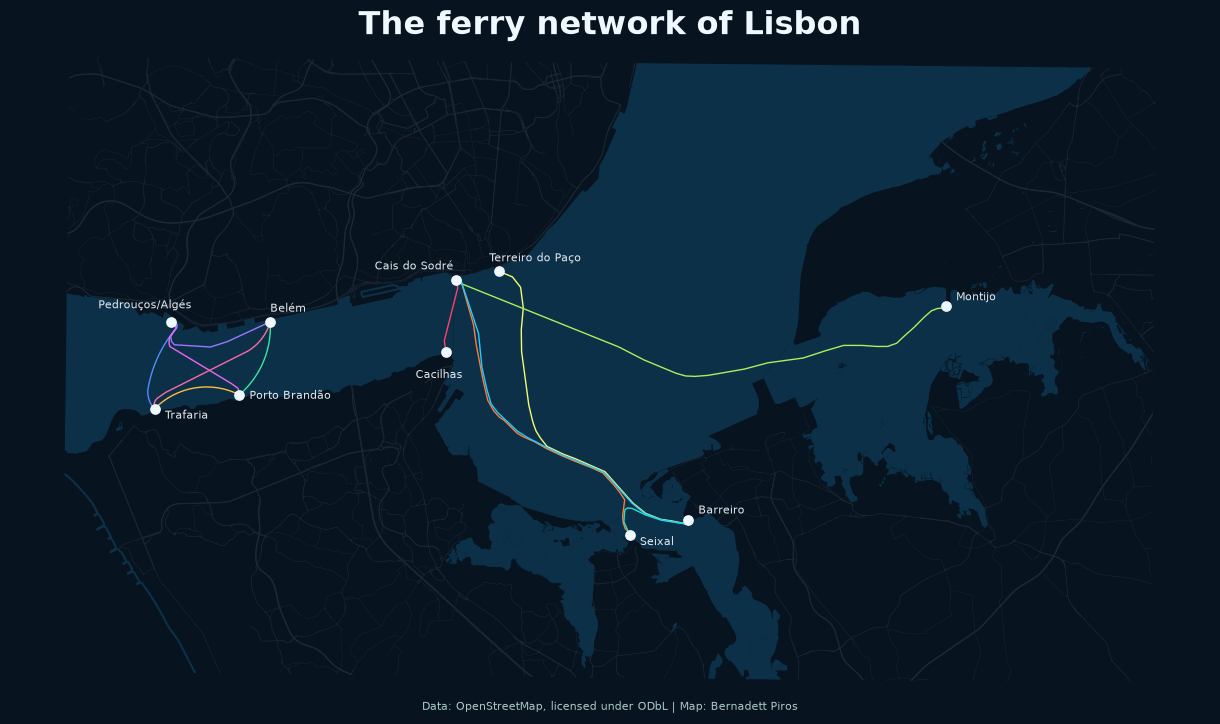

In [7]:
fig, ax = plt.subplots(figsize=(12, 8), facecolor="#07131F")

# Roads
roads.plot(ax=ax, color="#1f2a35", lw=roads["linewidth"], zorder=1)

# Water
water.plot(ax=ax, color="#0B3048", ec="none", zorder=1)

# Routes
routes.plot(ax=ax, color=routes["color"], lw=1, zorder=3)

# Terminals
terminals.plot(ax=ax, color="#F0F8FF", markersize=45, zorder=4)

# Terminal labels
label_offsets = {
    "Cais do Sodré": (-2000, 250),
    "Terreiro do Paço": (-250, 250),
    "Cacilhas": (-750, -650),
    "Montijo": (250, 150),
    "Seixal": (250, -250),
    "Barreiro": (250, 150),
    "Belém": (0, 250),
    "Pedrouços/Algés": (-1800, 350),
    "Porto Brandão": (250, -100),
    "Trafaria": (250, -250)
}

for i, row in terminals.iterrows():
    dx, dy = label_offsets[row["name"]]

    ax.text(row.geometry.x + dx, row.geometry.y + dy, row["name"],
            color="#E1E8ED", size=8, zorder=5)  

ax.set_facecolor("#07131F")
ax.set_aspect("equal")
ax.set_axis_off()

# Title
fig.text(0.5, 0.95,
         "The ferry network of Lisbon",
         color="#F0F8FF", size=23, weight="bold", ha="center", va="top")

# Caption
fig.text(
    0.5, 0.075,
    "Data: OpenStreetMap, licensed under ODbL | Map: Bernadett Piros", 
    color="#A7C8C3", size=8, ha="center")

plt.subplots_adjust(left=0, right=1, top=1, bottom=0)

plt.show()

#fig.savefig("ferry_network.png", bbox_inches="tight", pad_inches=0.2)